# Import and connections

In [1]:
import math
from typing import List, Union, Sequence
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import ParameterSampler, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Data loading

In [2]:
df  = pd.read_csv('wines.csv')
df.head(10)

,slug,title,alcohol,temperature,category,color,region,manufacturer,rating,grapes,dishes,description
0,135,135,14,16-18,Красное сухое,Красный,Крым,Усадьба Перовских,4.78,Мурведр|Сира,Мясо и стейки|Сыры,"Яркий аромат черных ягод, пряностей, перца, ва..."
1,1890-pino-nuar,1890 Пино Нуар,13,16-18,Красное сухое,Красный,Крым,Усадьба Перовских,4.86,Пино Нуар,Овощи гриль|Сыры,"В аромате черная смородина, ежевика, ноты крас..."
2,44-parallel,44 Параллель,13,16-18,Красное сухое,Красный,Крым,Усадьба Перовских,4.57,Каберне Совиньон|Мерло,Мясное ассорти|Мясо и стейки,"Аромат богатый, сложный с доминантой черной см..."
3,a-gordienko-m-nikolaev-pino-nuar-krasnoe-suhoe...,Пино Нуар,13,16-18,Красное сухое,Рубиново-красный,Кубань,А. Гордиенко & М. Николаев,NaN,Пино Нуар,Выпечка и десерты|Мясо и стейки|Сыры,Вкус: Ягодно-фруктовый. С тонами пряных лесных...
4,a-gordienko-m-nikolaev-sira-nuvo-krasnoe-suhoe...,Сира Нуво,11,16-18,Красное сухое,Вишнево-рубиновый,Кубань,А. Гордиенко & М. Николаев,NaN,Сира,Мясо и стейки|Сыры,Вкус: Элегантный с россыпью северных ягод. Пряный
5,abrau-dyurso-abrau-durso-brut-rose-reserve-pin...,Abrau-Durso Brut Rose Reserve,12,8-10,Белое брют,Насыщенный розовый,Кубань,Абрау-Дюрсо,5.00,Каберне Совиньон|Каберне Фран|Мерло|Пино Нуар|...,Легкие закуски|Морепродукты|Сыры,"В аромате красные лесные ягоды — малина, вишня..."
6,abrau-dyurso-abrau-durso-reserve-brut-shardone...,Abrau-Durso Reserve Brut,11,8-10,Белое брют,Золотистый,Кубань,Абрау-Дюрсо,5.00,Пино Блан|Рислинг|Шардоне,Легкие закуски|Морепродукты,"В аромате тона зеленого яблока, груши вильямс ..."
7,abrau-dyurso-abrau-dyurso-pino-nuar-krasnoe-su...,Абрау-Дюрсо Пино Нуар,13,16-18,Красное сухое,"Светло-рубиновый, прозрачный",Кубань,Абрау-Дюрсо,5.00,Пино Нуар,Мясо и стейки|Сыры,"Аромат тонкий — вишня, малина, лёгкие нотки зе..."
8,abrau-dyurso-abrau-estates-amurskiy-potapenko-...,Abrau Estates Амурский Потапенко,10,16-18,Красное сухое,Рубиновый с пурпурным оттенком,Кубань,Абрау-Дюрсо,5.00,Амурский Потапенко,Мясное ассорти|Сыры,"В аромате цветочные ноты пионов и фиалок, тона..."
9,abrau-dyurso-abrau-estates-beloe-shardone-suho...,Abrau Estates белое,12,10-12,Белое сухое,Светло-соломенный,Кубань,Абрау-Дюрсо,5.00,Рислинг|Уньи блан|Шардоне,BBQ|Морепродукты|Салаты,"В аромате ноты белого персика, свежих тропичес..."


In [3]:
df.shape

(2110, 12)

# Data preparing

у нас есть выбросы: некотоыре вина имеют процент алкоголя больше 100 процентов. Вероятно, забыли поставить точку

In [4]:
display(df[df["alcohol"] > 20])


,slug,title,alcohol,temperature,category,color,region,manufacturer,rating,grapes,dishes,description
605,esse-rkatsiteli-oranzh-beloe-suhoe-12,Ркацители Оранж,135,11-13,Белое сухое,Золотисто-медовый,Крым,ESSE,5.00,Ркацители,Мясо и стейки|Рыба и морепродукты|Салаты,"Вкус: Карамельно-финиковый, ореховый бисквит с..."
842,integral,Integral,135,15-18,Красное сухое,Темно-рубиновый,Крым,One Barrel by Dmitry Maslov (OBDM),5.00,Каберне Фран,Брускетты|Запеченные овощи|Мясное ассорти|Мясо...,"Сочный, пряный Каберне Фран с характером южног..."
1100,muskat-ottonel-gusev,Мускат Оттонель Гусевъ,108,8-10,Белое брют,Соломенный,Нижняя Волга,Гусевъ,5.00,Мускат Оттонель,Блюда из птицы|Легкие закуски,"Аромат: парфюмерный, с оттенками спелого виног..."
1409,simbioz,Симбиоз,135,15-18,Красное сухое,Темно-рубиновый,Крым,WINEPARK,4.81,Каберне Совиньон,BBQ|Запеченные овощи|Мясное ассорти|Мясо и сте...,В аромате красные и темные спелые ягоды (сморо...


In [5]:
df["alcohol"] = df["alcohol"].astype(float)
df.loc[df["alcohol"] > 20, "alcohol"] /= 10

удаляем строки с неизвестным рейтингом


In [6]:
print("\nПропущенные значения:")
display(df.isnull().sum())


Пропущенные значения:


slug              0
title             0
alcohol           0
temperature       0
category          0
color             0
region            0
manufacturer      0
rating          632
grapes            0
dishes            0
description       0
dtype: int64

In [7]:
df_model = df.dropna(subset=["rating"]).copy()
df_unknown = df[df["rating"].isna()].copy()

In [8]:
def n_min(r, n_max=10_000):
    r100 = round(r * 100)
    for n in range(1, n_max + 1):
        s = -(-n * (2 * r100 - 1) // 200)      # ceil(n*(r-0.005))
        if 200 * s < n * (2 * r100 + 1):        # s/n < r+0.005
            return n
    return None

In [9]:
df_model["n_min"] = df_model["rating"].apply(n_min)

In [10]:
df_model.head(5)

,slug,title,alcohol,temperature,category,color,region,manufacturer,rating,grapes,dishes,description,n_min
0,135,135,14.0,16-18,Красное сухое,Красный,Крым,Усадьба Перовских,4.78,Мурведр|Сира,Мясо и стейки|Сыры,"Яркий аромат черных ягод, пряностей, перца, ва...",9
1,1890-pino-nuar,1890 Пино Нуар,13.0,16-18,Красное сухое,Красный,Крым,Усадьба Перовских,4.86,Пино Нуар,Овощи гриль|Сыры,"В аромате черная смородина, ежевика, ноты крас...",7
2,44-parallel,44 Параллель,13.0,16-18,Красное сухое,Красный,Крым,Усадьба Перовских,4.57,Каберне Совиньон|Мерло,Мясное ассорти|Мясо и стейки,"Аромат богатый, сложный с доминантой черной см...",7
5,abrau-dyurso-abrau-durso-brut-rose-reserve-pin...,Abrau-Durso Brut Rose Reserve,12.0,8-10,Белое брют,Насыщенный розовый,Кубань,Абрау-Дюрсо,5.00,Каберне Совиньон|Каберне Фран|Мерло|Пино Нуар|...,Легкие закуски|Морепродукты|Сыры,"В аромате красные лесные ягоды — малина, вишня...",1
6,abrau-dyurso-abrau-durso-reserve-brut-shardone...,Abrau-Durso Reserve Brut,11.0,8-10,Белое брют,Золотистый,Кубань,Абрау-Дюрсо,5.00,Пино Блан|Рислинг|Шардоне,Легкие закуски|Морепродукты,"В аромате тона зеленого яблока, груши вильямс ...",1


Дропаем лишние колонки

In [11]:
names = df_model["title"].copy()          # сохраняем названия для разбора ошибок модели позже
df_model = df_model.drop(columns=["slug", "title"])

## category - разбивка на цвет и сладость

In [12]:
print(df_model["category"].value_counts())

category
Красное сухое          518
Белое сухое            388
Розовое сухое          113
Белое брют             110
Белое экстра брют       53
Белое полусладкое       47
Белое полусухое         39
Розовое брют            37
Белое сладкое           33
Красное полусладкое     27
Красное сладкое         23
Розовое полусухое       23
Розовое экстра брют     19
Розовое полусладкое     15
Красное полусухое       12
Оранжевое сухое         11
Розовое сладкое          6
Красное брют             3
Красное экстра брют      1
Name: count, dtype: int64


In [13]:
parts = df_model["category"].str.split(" ", n=1, expand=True)
df_model["wine_color"] = parts[0]            # первое слово: Красное / Белое / Розовое ...
df_model["sweetness"] = parts[1]             # всё остальное: сухое / брют / полусладкое ...

print(df_model[["category", "wine_color", "sweetness"]].drop_duplicates())

                 category wine_color    sweetness
0           Красное сухое    Красное        сухое
5              Белое брют      Белое         брют
9             Белое сухое      Белое        сухое
13        Оранжевое сухое  Оранжевое        сухое
14          Розовое сухое    Розовое        сухое
15    Красное полусладкое    Красное  полусладкое
24           Розовое брют    Розовое         брют
27      Белое полусладкое      Белое  полусладкое
44        Белое полусухое      Белое    полусухое
60        Красное сладкое    Красное      сладкое
67    Розовое полусладкое    Розовое  полусладкое
75      Белое экстра брют      Белое  экстра брют
138     Красное полусухое    Красное    полусухое
142         Белое сладкое      Белое      сладкое
161     Розовое полусухое    Розовое    полусухое
181   Розовое экстра брют    Розовое  экстра брют
650          Красное брют    Красное         брют
681       Розовое сладкое    Розовое      сладкое
2018  Красное экстра брют    Красное  экстра брют


In [14]:
df_model = df_model.drop(columns="category")

## Temperature

temperature: 16-18 делаем два числа

In [15]:
temp = df_model["temperature"].str.replace("–", "-", regex=False).str.split("-", expand=True) # заменяем длинное тире на дефис, потом делим строку
df_model["temp_min"] = pd.to_numeric(temp[0], errors="coerce")
df_model["temp_max"] = pd.to_numeric(temp[1], errors="coerce")
df_model["temp_max"] = df_model["temp_max"].fillna(df_model["temp_min"]) # заполняет пропуски в temp_max значениями из temp_min той же строки


In [16]:
df_model = df_model.drop(columns="temperature")

## grapes (сорта) и dishes(блюда): строка с разделителем | → список

In [17]:
def to_list(text):
    if pd.isna(text) or text == "":
        return []                       # пустое значение = пустой список
    return text.split("|")

In [18]:
df_model["grapes"] = df_model["grapes"].apply(to_list)
df_model["dishes"] = df_model["dishes"].apply(to_list)

In [19]:
display(df_model[["grapes", "dishes"]].head())

,grapes,dishes
0,"[Мурведр, Сира]","[Мясо и стейки, Сыры]"
1,[Пино Нуар],"[Овощи гриль, Сыры]"
2,"[Каберне Совиньон, Мерло]","[Мясное ассорти, Мясо и стейки]"
5,"[Каберне Совиньон, Каберне Фран, Мерло, Пино Н...","[Легкие закуски, Морепродукты, Сыры]"
6,"[Пино Блан, Рислинг, Шардоне]","[Легкие закуски, Морепродукты]"


## Дропнем цвет. Там чушь по типу "Глубокий темно-рубиновый с фиолетовым отливом". Для цвета оставляем только wine_color

In [20]:
df_model = df_model.drop(columns="color")


In [21]:
df_model.head(5)

,alcohol,region,manufacturer,rating,grapes,dishes,description,n_min,wine_color,sweetness,temp_min,temp_max
0,14.0,Крым,Усадьба Перовских,4.78,"[Мурведр, Сира]","[Мясо и стейки, Сыры]","Яркий аромат черных ягод, пряностей, перца, ва...",9,Красное,сухое,16,18.0
1,13.0,Крым,Усадьба Перовских,4.86,[Пино Нуар],"[Овощи гриль, Сыры]","В аромате черная смородина, ежевика, ноты крас...",7,Красное,сухое,16,18.0
2,13.0,Крым,Усадьба Перовских,4.57,"[Каберне Совиньон, Мерло]","[Мясное ассорти, Мясо и стейки]","Аромат богатый, сложный с доминантой черной см...",7,Красное,сухое,16,18.0
5,12.0,Кубань,Абрау-Дюрсо,5.00,"[Каберне Совиньон, Каберне Фран, Мерло, Пино Н...","[Легкие закуски, Морепродукты, Сыры]","В аромате красные лесные ягоды — малина, вишня...",1,Белое,брют,8,10.0
6,11.0,Кубань,Абрау-Дюрсо,5.00,"[Пино Блан, Рислинг, Шардоне]","[Легкие закуски, Морепродукты]","В аромате тона зеленого яблока, груши вильямс ...",1,Белое,брют,8,10.0


## Region & Manufacturer

In [22]:
print("region:", df_model["region"].nunique())
print("manufacturer:", df_model["manufacturer"].nunique())
print(df_model["region"].value_counts().head(15))
print(df_model["manufacturer"].value_counts().head(15))

region: 9
manufacturer: 121
region
Кубань                      823
Крым                        450
Дагестан                     95
Долина Дона                  36
Ставрополье                  30
Самара                       21
Нижняя Волга                 18
Северная Осетия — Алания      4
Дальневосточная зона          1
Name: count, dtype: int64
manufacturer
винный дом «Фанагория»      100
Кубань-Вино                  79
Дербент Вино                 61
Усадьба Перовских            51
Мысхако                      46
Массандра                    39
Абрау-Дюрсо                  38
Alma Valley                  37
АРАТТИ                       30
Шато Пино                    27
Chateau de Talu              26
Château Le Grand Vostock     26
Усадьба Мезыбь               26
Собер Баш                    25
Раевское                     23
Name: count, dtype: int64


получили много регионов, некоторые из них имеют мало вин. После сплита редкие регионы отнесем в категорию other

In [23]:
df_model["manufacturer"] = df_model["manufacturer"].str.strip()
print(sorted(df_model["manufacturer"].unique()))

['AGORA WINERY', 'AYA Organic Wine & Vineyards', 'Alma Valley', 'Andryus Yutsis', 'Bakla Vines', 'Belmas Winery', 'Bogovich Wine & Vineyard', 'Cellar Master', 'Chateau Andre', 'Chateau de Talu', 'Château Le Grand Vostock', 'Cloudy Winery', "Cock t'est belle", 'Denisov Winery', 'Domaine Lipko', 'Domaine de la Vivandiere', 'Dubinin Winery', 'ESSE', 'Ferrum Winery', 'GAVRAS', 'Golubitskoe Estate', 'Gunko Winery', 'JD winery', 'KATHARON', 'Kalos Limen', 'LETO', 'Le K2', 'LeGato', 'Loco Cimbali', 'MILLSTREAM', 'Mancopia', 'Mantra Estate', 'Mons Albus', 'Nesterov Winery', 'Oleg Repin', 'Olymp Winery', 'One Barrel by Dmitry Maslov (OBDM)', 'Rem Akchurin', 'STN Winery', 'Tempelhof Winery', 'Uppa Winery', 'Uva Vallis', 'Vibes', 'Villa di Alma', 'VinaBani', 'Vino & Nebo', 'WINEMAFIA', 'WINEPARK', 'Yaiyla Winery', 'АРАТТИ', 'Абрау-Дюрсо', 'Агролайн', 'Артвин', 'Бельбек', 'В2Р', 'ВайнКрафт', 'Валерий Захарьин', 'Ведерниковъ', 'Виктор Сташко', 'Вилла София', 'Вилла Уркуста', 'Вина Арпачина', 'Виног

Пара «Golubitskoe Estate» и "Поместье Голубицкое" - один и тот же производитель

In [24]:
df_model["manufacturer"] = df_model["manufacturer"].replace(
    {"Golubitskoe Estate": "Поместье Голубицкое"}
)

## Description

Пока непонятно нужно ли это

In [25]:
df_model['description'].head(15)

0     Яркий аромат черных ягод, пряностей, перца, ва...
1     В аромате черная смородина, ежевика, ноты крас...
2     Аромат богатый, сложный с доминантой черной см...
5     В аромате красные лесные ягоды — малина, вишня...
6     В аромате тона зеленого яблока, груши вильямс ...
7     Аромат тонкий — вишня, малина, лёгкие нотки зе...
8     В аромате цветочные ноты пионов и фиалок, тона...
9     В аромате ноты белого персика, свежих тропичес...
10    В аромате джемовые ноты красных ягод: смородин...
11    В аромате тона белой сливы, крыжовника и весен...
12    В аромате фрукты, табак, чернослив, шоколад и ...
13    В аромате медовые и цитрусовые оттенки, ноты с...
14    В аромате тона свежей клубники, спелой малины ...
15    В аромате красные ягоды и вишнево-смородиновый...
16    В аромате фруктовые ноты с деликатными тонами ...
Name: description, dtype: object

Большой дисбаланс классов с рейтингом 5.0. Разбиваем на бины

In [26]:
rating_bins = pd.cut(df_model["rating"], bins=[0, 4.0, 4.8, 4.99, 5.0])
print(rating_bins.value_counts())

rating
(4.99, 5.0]    1046
(4.0, 4.8]      164
(0.0, 4.0]      136
(4.8, 4.99]     132
Name: count, dtype: int64


# Data analysis

Размер и типы

In [27]:
print("Размер:", df_model.shape)
df_model.info()

Размер: (1478, 12)
<class 'pandas.core.frame.DataFrame'>
Index: 1478 entries, 0 to 2101
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   alcohol       1478 non-null   float64
 1   region        1478 non-null   object 
 2   manufacturer  1478 non-null   object 
 3   rating        1478 non-null   float64
 4   grapes        1478 non-null   object 
 5   dishes        1478 non-null   object 
 6   description   1478 non-null   object 
 7   n_min         1478 non-null   int64  
 8   wine_color    1478 non-null   object 
 9   sweetness     1478 non-null   object 
 10  temp_min      1478 non-null   int64  
 11  temp_max      1478 non-null   float64
dtypes: float64(3), int64(2), object(7)
memory usage: 150.1+ KB


Пропуски по колонкам (только те, где они есть)


In [28]:
missing = df_model.isnull().sum()
print(missing[missing > 0])

Series([], dtype: int64)


Статистика по числовым признакам

In [29]:

df_model[["alcohol", "temp_min", "temp_max", "rating", "n_min"]].describe()

,alcohol,temp_min,temp_max,rating,n_min
count,1478.000000,1478.000000,1478.000000,1478.000000,1478.000000
mean,12.412246,11.378214,13.523004,4.804635,2.828823
std,1.356298,3.602412,3.548743,0.490568,5.415798
min,7.000000,4.000000,6.000000,1.000000,1.000000
25%,12.000000,8.000000,10.000000,4.900000,1.000000
50%,12.000000,10.000000,12.000000,5.000000,1.000000
75%,13.000000,16.000000,18.000000,5.000000,1.000000
max,19.000000,18.000000,22.000000,5.000000,67.000000


Сколько вин попало в каждый диапазон рейтинга

rating
(0.0, 4.0]      136
(4.0, 4.8]      164
(4.8, 4.99]     132
(4.99, 5.0]    1046
Name: count, dtype: int64


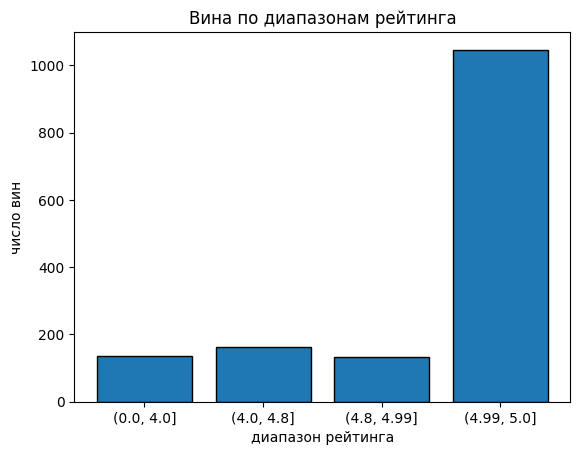

In [30]:

rating_bins = pd.cut(df_model["rating"], bins=[0, 4.0, 4.8, 4.99, 5.0])
counts = rating_bins.value_counts().sort_index()
print(counts)

plt.bar(counts.index.astype(str), counts.values, edgecolor="black")
plt.xlabel("диапазон рейтинга")
plt.ylabel("число вин")
plt.title("Вина по диапазонам рейтинга")
plt.show()

Гистограммы числовых признаков

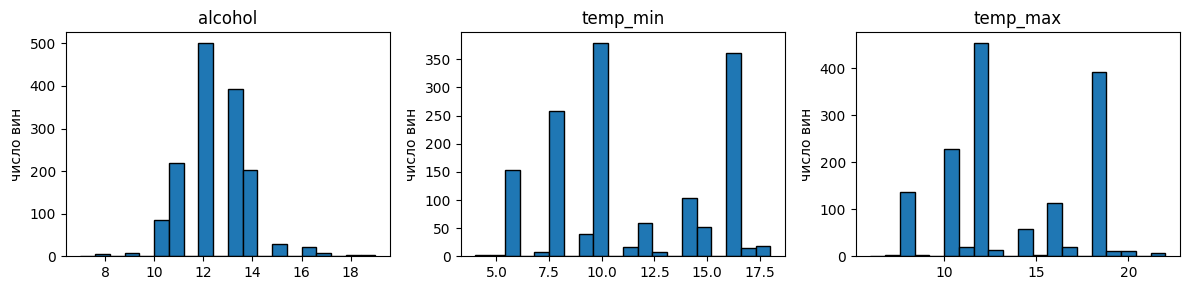

In [31]:

num_cols = ["alcohol", "temp_min", "temp_max"]

fig, axes = plt.subplots(1, len(num_cols), figsize=(12, 3))
for ax, col in zip(axes, num_cols):
    ax.hist(df_model[col].dropna(), bins=20, edgecolor="black")
    ax.set_title(col)
    ax.set_ylabel("число вин")
plt.tight_layout()
plt.show()

Корреляция Спирмена между числовыми признаками и рейтингом

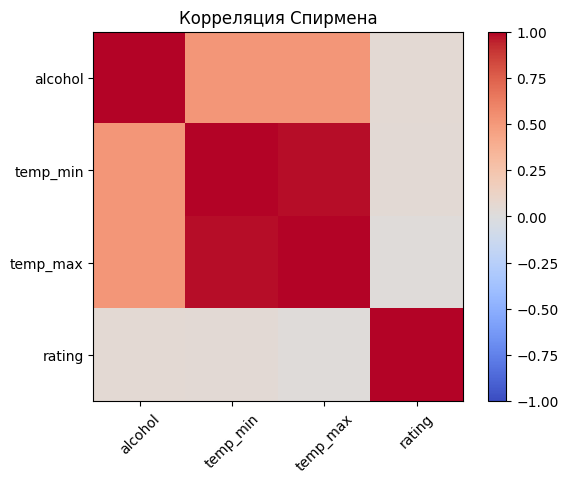

In [32]:

corr = df_model[num_cols + ["rating"]].corr(method="spearman")

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45)
plt.yticks(range(len(corr)), corr.columns)
plt.title("Корреляция Спирмена")
plt.show()

## Cредний рейтинг у самых частых производителей


## Категориальные: таблица по группам


In [33]:
def group_summary(df, col, min_count=5):
    g = df.groupby(col)["rating"].agg(
        count="count",
        mean="mean",
    )
    return g[g["count"] >= min_count].sort_values("mean")

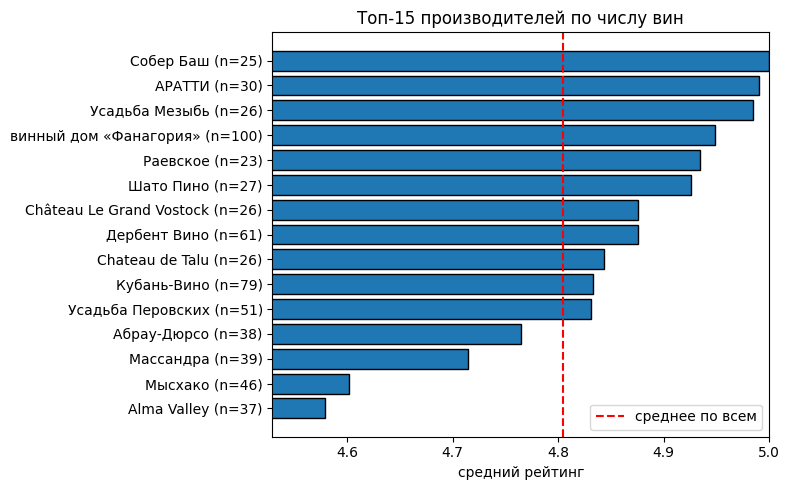

In [34]:
top_n = 15
g = group_summary(df_model, "manufacturer", min_count=10)
g = g.sort_values("count", ascending=False).head(top_n).sort_values("mean")

labels = [f"{name} (n={int(c)})" for name, c in zip(g.index, g["count"])]

plt.figure(figsize=(8, 5))
plt.barh(labels, g["mean"], edgecolor="black")
plt.axvline(df_model["rating"].mean(), color="red", linestyle="--", label="среднее по всем")
plt.xlim(g["mean"].min() - 0.05, 5.0)
plt.xlabel("средний рейтинг")
plt.title(f"Топ-{top_n} производителей по числу вин")
plt.legend()
plt.tight_layout()
plt.show()

То же самое для регионов

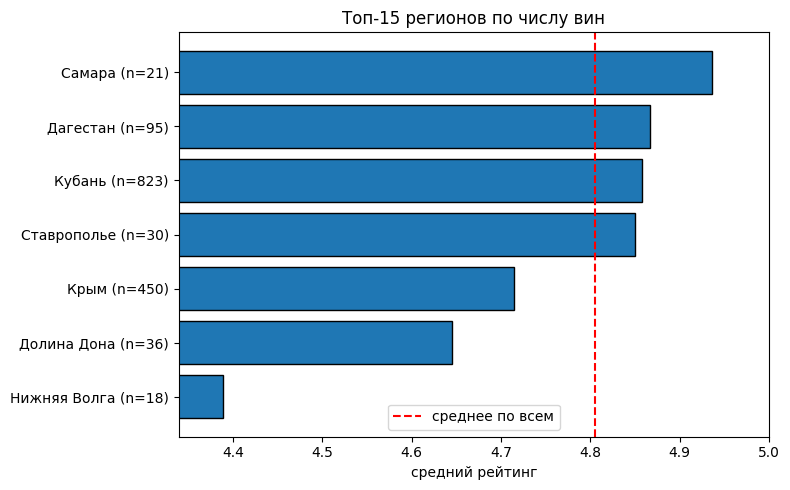

In [35]:

g = group_summary(df_model, "region", min_count=10)
g = g.sort_values("count", ascending=False).head(top_n).sort_values("mean")

labels = [f"{name} (n={int(c)})" for name, c in zip(g.index, g["count"])]

plt.figure(figsize=(8, 5))
plt.barh(labels, g["mean"], edgecolor="black")
plt.axvline(df_model["rating"].mean(), color="red", linestyle="--", label="среднее по всем")
plt.xlim(g["mean"].min() - 0.05, 5.0)
plt.xlabel("средний рейтинг")
plt.title(f"Топ-{top_n} регионов по числу вин")
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
# сводно: какую долю разброса рейтинга объясняет каждый категориальный признак

def explained_share(df, col, min_count=5):
    sizes = df.groupby(col)["rating"].transform("count")
    d = df[sizes >= min_count]               # группы из 1-2 вин "объясняют" сами себя, их убираем
    group_mean = d.groupby(col)["rating"].transform("mean")
    ss_total = ((d["rating"] - d["rating"].mean()) ** 2).sum()
    ss_resid = ((d["rating"] - group_mean) ** 2).sum()
    return 1 - ss_resid / ss_total


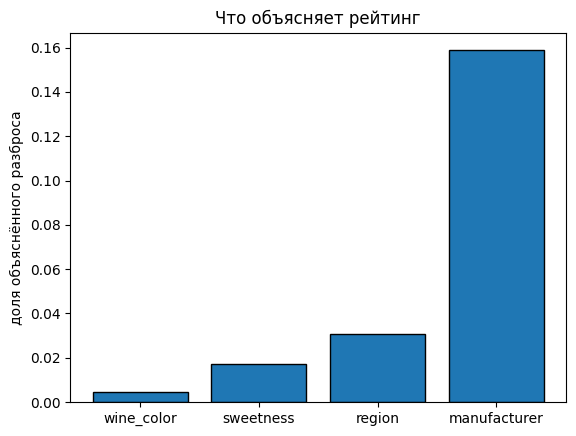

In [37]:

cat_cols = ["wine_color", "sweetness", "region", "manufacturer"]
shares = [explained_share(df_model, col) for col in cat_cols]

plt.bar(cat_cols, shares, edgecolor="black")
plt.ylabel("доля объяснённого разброса")
plt.title("Что объясняет рейтинг")
plt.show()

Вывод: Если для каждого вина предсказывать средний рейтинг его производителя, а не общий средний, сумма квадратов ошибок падает на 16%.
То есть знание производителя делает предсказания лучше, но ненамного. 84% осталась.

## Сорта винограда и блюда

### Сорта винограда

In [38]:
# сколько всего разных сортов и блюд, и у скольких вин списки пустые
for col in ["grapes", "dishes"]:
    all_items = df_model[col].explode().dropna()
    print(f"{col}: уникальных = {all_items.nunique()}, "
          f"вин с пустым списком = {(df_model[col].str.len() == 0).sum()}")

grapes: уникальных = 128, вин с пустым списком = 0
dishes: уникальных = 34, вин с пустым списком = 0


In [39]:
# таблица: для каждого сорта/блюда число вин и средний рейтинг
def list_summary(df, col, min_count=10):
    e = df[[col, "rating"]].explode(col).dropna(subset=[col])   # одна строка = одно вино + один сорт
    g = e.groupby(col)["rating"].agg(count="count", mean="mean")
    return g[g["count"] >= min_count]

Топ-15 самых частых сортов винограда

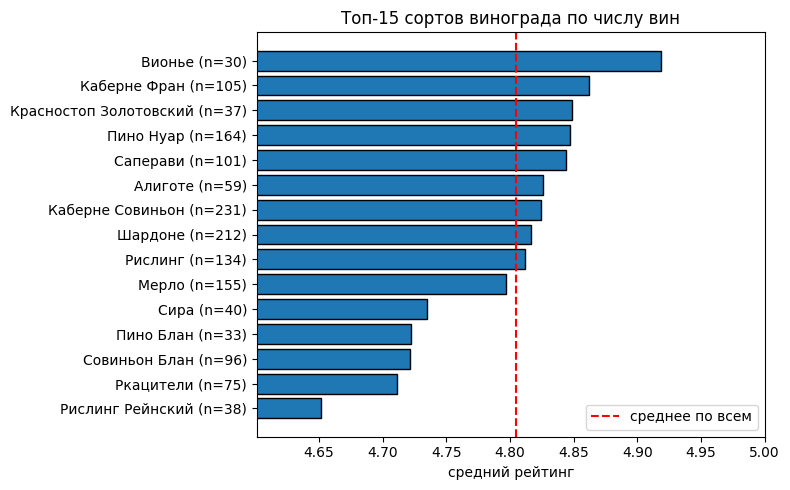

In [40]:
top_n = 15
g = list_summary(df_model, "grapes")
g = g.sort_values("count", ascending=False).head(top_n).sort_values("mean")

labels = [f"{name} (n={int(c)})" for name, c in zip(g.index, g["count"])]

plt.figure(figsize=(8, 5))
plt.barh(labels, g["mean"], edgecolor="black")
plt.axvline(df_model["rating"].mean(), color="red", linestyle="--", label="среднее по всем")
plt.xlim(g["mean"].min() - 0.05, 5.0)
plt.xlabel("средний рейтинг")
plt.title(f"Топ-{top_n} сортов винограда по числу вин")
plt.legend()
plt.tight_layout()
plt.show()

### Блюда

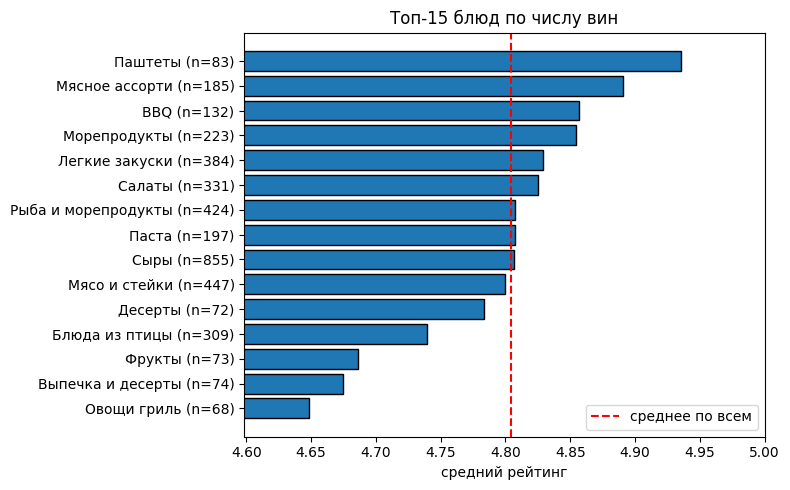

In [41]:
g = list_summary(df_model, "dishes")
g = g.sort_values("count", ascending=False).head(top_n).sort_values("mean")

labels = [f"{name} (n={int(c)})" for name, c in zip(g.index, g["count"])]

plt.figure(figsize=(8, 5))
plt.barh(labels, g["mean"], edgecolor="black")
plt.axvline(df_model["rating"].mean(), color="red", linestyle="--", label="среднее по всем")
plt.xlim(g["mean"].min() - 0.05, 5.0)
plt.xlabel("средний рейтинг")
plt.title(f"Топ-{top_n} блюд по числу вин")
plt.legend()
plt.tight_layout()
plt.show()

## Общий вывод

- Рейтинг сильно перекошен: у 71% вин он ровно 5.0
- Числовые признаки (alcohol, temp_min, temp_max) по Спирмену с рейтингом не связаны
- Среди категориальных признаков заметный сигнал даёт производитель. Объясняет 16% разброса. Регион слабее, 4%, цвет и сладость почти ничего
- Сорта винограда: лучше всего для рейтинга показали себя сорта Вионье, Каберне Фран и Красностоп Золотовский. Хуже всего сорт Рислинг Рейнский
- Рекомендуемые блюда: лучше всего для рейтинга показали себя блюда: паштет, мясное ассорти, BBQ (сокрещение от barbecue). Хуже всего овощи гриль
- Рейтинги с малым числом голосов ненадёжны, поэтому вводим веса по n_min. Степень доверия задаётся параметром alpha и будет подбираться по valid.

# Models

## Model building

In [42]:
class MLP(nn.Module):
    def __init__(self,
                 inputShape: Union[int, Sequence[int]],   # число признаков или любая форма входа. например для картинок [28, 28] MNIST
                 hiddenShape: List[int],                  # ширины скрытых слоёв: длина списка = глубина. Например [64, 32] это 2 слоя
                 outputShape: int = 1,                    # 1 для регрессии, число классов для классификации
                 fActivation=nn.Tanh,                     # функция активации
                 fOutput=nn.Identity):                    # активация на выход по умолчанию никакой
        super().__init__()

        if len(hiddenShape) == 0:
            raise ValueError("hiddenShape должен содержать хотя бы один слой")

        # вход может быть числом табличные данные или формой (28, 28): считаем число входов
        inputSize = inputShape if isinstance(inputShape, int) else math.prod(inputShape)

        self.inputModule = nn.Sequential(
            nn.Flatten(), # оставляет первую ось (размер пачки) и разворачивает всё остальное в одну строку. Для картинки (32, 28, 28) получим (32, 784). Для таблицы (8, 300) ничего не меняется, потому что она уже плоская
            nn.Linear(inputSize, hiddenShape[0]),
            fActivation())

        self.hiddenModule = nn.Sequential(
            *[nn.Sequential(nn.Linear(hiddenShape[i], hiddenShape[i + 1]),
                            fActivation()) for i in range(len(hiddenShape) - 1)])

        self.outputModule = nn.Sequential(
            nn.Linear(hiddenShape[-1], outputShape),
            fOutput())

    def forward(self, x):
        x = self.inputModule(x)
        x = self.hiddenModule(x)
        x = self.outputModule(x)
        return x

In [43]:
SEED = 42

MODEL_CONFIG = {
    "hiddenShape":  [128, 128, 64, 32], #[128, 64, 32] , [64, 32] [128, 128, 64, 32]
    "outputShape": 1, # тк задача - регрессия и предсказывается 1 число
    "fActivation":  nn.Tanh, # nn.Tanh ,  nn.ReLU , nn.GELU
    "fOutput": nn.Identity, #  функция активации выходного слоя. Identity ничего не меняет
}

In [44]:
torch.manual_seed(SEED)                # чтобы начальные веса были одинаковыми при каждом запуске



## Data splitting


In [45]:
# параметры сплита
SEED = 42
TEST_SIZE = 0.15
VALID_SIZE = 0.15
BIN_EDGES = [0, 4.0, 4.8, 4.99, 5.0]   # по этим диапазонам рейтинга стратифицируем

rating_bins = pd.cut(df_model["rating"], bins=BIN_EDGES) # qcut 
print(rating_bins.value_counts().sort_index())

rating
(0.0, 4.0]      136
(4.0, 4.8]      164
(4.8, 4.99]     132
(4.99, 5.0]    1046
Name: count, dtype: int64


In [46]:
# 1) отделяем test
train_valid_df, test_df = train_test_split(
    df_model,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=rating_bins,
)

# 2) из остатка отделяем valid (доля пересчитана от остатка)
valid_rel = VALID_SIZE / (1 - TEST_SIZE)
train_df, valid_df = train_test_split(
    train_valid_df,
    test_size=valid_rel,
    random_state=SEED,
    stratify=rating_bins.loc[train_valid_df.index],
)


In [47]:
print(train_df.dtypes)
print()
print("пропуски в train:")
missing = train_df.isnull().sum()
print(missing[missing > 0])

alcohol         float64
region           object
manufacturer     object
rating          float64
grapes           object
dishes           object
description      object
n_min             int64
wine_color       object
sweetness        object
temp_min          int64
temp_max        float64
dtype: object

пропуски в train:
Series([], dtype: int64)


In [48]:
TARGET = "rating"
WEIGHT_SRC = "n_min"

NUM_COLS = ["alcohol", "temp_min", "temp_max"]
CAT_COLS = ["wine_color", "sweetness", "region", "manufacturer"]
LIST_COLS = ["grapes", "dishes"]

all_cols = [TARGET, WEIGHT_SRC] + NUM_COLS + CAT_COLS + LIST_COLS


In [49]:
scaler = StandardScaler()
scaler.fit(train_df[NUM_COLS])          # среднее и отклонение считаются только по train

X_num_train = scaler.transform(train_df[NUM_COLS])
X_num_valid = scaler.transform(valid_df[NUM_COLS])
X_num_test = scaler.transform(test_df[NUM_COLS])


### Обработка категориальных признаков

In [50]:

MIN_COUNT_CAT = 5    # меньше стольких вин в train = значение считается редким

cat_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",   # значения, которых не было в train, идут в "редкие"
    min_frequency=MIN_COUNT_CAT,
    sparse_output=False,                    # обычный массив, а не разреженный
)
cat_encoder.fit(train_df[CAT_COLS])         # правила считаются только по train

X_cat_train = cat_encoder.transform(train_df[CAT_COLS])
X_cat_valid = cat_encoder.transform(valid_df[CAT_COLS])
X_cat_test = cat_encoder.transform(test_df[CAT_COLS])

print(X_cat_train.shape, X_cat_valid.shape, X_cat_test.shape)

(1034, 83) (222, 83) (222, 83)


In [51]:
# сколько значений в каждой колонке и сколько из них оказались редкими
for col, cats, rare in zip(CAT_COLS, cat_encoder.categories_, cat_encoder.infrequent_categories_):
    n_rare = 0 if rare is None else len(rare)
    print(f"{col}: значений {len(cats)}, редких {n_rare}")

wine_color: значений 4, редких 0
sweetness: значений 6, редких 0
region: значений 9, редких 2
manufacturer: значений 113, редких 49


### Grapes и dishes

Применяем multi-hot. Тот же one-hot, только у вина может быть несколько единиц сразу. Например, вино из каберне и мерло получает 1 в колонках обоих сортов.

Редкие сорта и блюда просто отбрасываем

In [52]:
from collections import Counter
from sklearn.preprocessing import MultiLabelBinarizer

MIN_COUNT_LIST = 10     # значение должно встретиться минимум у стольких вин в train

def fit_list_encoder(series, min_count):
    # считаем, у скольких вин встречается каждое значение (только по train)
    counts = Counter(item for lst in series for item in lst)
    keep = sorted(item for item, c in counts.items() if c >= min_count)
    mlb = MultiLabelBinarizer(classes=keep)
    mlb.fit(series)
    return mlb

def encode_lists(series, mlb):
    # выкидываем значения, которых нет среди частых из train, потом кодируем
    known = set(mlb.classes_)
    filtered = [[x for x in lst if x in known] for lst in series]
    return mlb.transform(filtered)

In [53]:
list_encoders = {}
X_list_train, X_list_valid, X_list_test = [], [], []

for col in LIST_COLS:
    list_encoders[col] = fit_list_encoder(train_df[col], MIN_COUNT_LIST)
    X_list_train.append(encode_lists(train_df[col], list_encoders[col]))
    X_list_valid.append(encode_lists(valid_df[col], list_encoders[col]))
    X_list_test.append(encode_lists(test_df[col], list_encoders[col]))
    print(f"{col}: оставили {len(list_encoders[col].classes_)} значений")

# склеиваем колонки grapes и dishes в одну матрицу на каждый набор
X_list_train = np.hstack(X_list_train)
X_list_valid = np.hstack(X_list_valid)
X_list_test = np.hstack(X_list_test)
print(X_list_train.shape, X_list_valid.shape, X_list_test.shape)

# сколько вин в train остались вообще без единицы в списках
print("вин без единиц:", (X_list_train.sum(axis=1) == 0).sum())

grapes: оставили 26 значений
dishes: оставили 30 значений
(1034, 56) (222, 56) (222, 56)
вин без единиц: 0


### Собираем в матрицу и переводим в тензоры

In [54]:
def build_matrix(X_num, X_cat, X_list):
    # склеиваем колонки: сначала числовые, потом категории, потом сорта и блюда
    return np.hstack([X_num, X_cat, X_list]).astype(np.float32)   # float32 нужен весам Linear

def to_tensors(df, X):
    x = torch.from_numpy(X)
    y = torch.from_numpy(df[TARGET].to_numpy(dtype=np.float32))
    n = torch.from_numpy(df[WEIGHT_SRC].to_numpy(dtype=np.float32))   # n_min, вес посчитаем позже
    return x, y, n

In [55]:
x_train, y_train, n_train = to_tensors(train_df, build_matrix(X_num_train, X_cat_train, X_list_train))

x_valid, y_valid, n_valid = to_tensors(valid_df, build_matrix(X_num_valid, X_cat_valid, X_list_valid))

x_test, y_test, n_test = to_tensors(test_df, build_matrix(X_num_test, X_cat_test, X_list_test))

In [56]:


from sklearn.preprocessing import StandardScaler

scaler_y = StandardScaler()

scaler_y.fit(y_train.reshape(-1, 1))

,copy,True
,with_mean,True
,with_std,True


In [57]:
N_FEATURES = x_train.shape[1]
model = MLP(inputShape=N_FEATURES, **MODEL_CONFIG)

## Model fitting

In [58]:
LR = 1e-3
EPOCHS = 140
BATCH_SIZE = 64
ALPHA = 0.1          # степень недоверия к рейтингам с малым n_min: 0 = веса одинаковые. 0.1 - низкое недоверие к малым голосам
LOSS_FN = nn.L1Loss  # какой loss: nn.L1Loss (по модулю) или nn.MSELoss (по квадрату)

Насоклько сильно будем не доверять рейтингу с n_min = 1? Как будет эффективнее заранее нельзя сказать, поэтому степень недоверия ALPHA делаем гиперпараметром

| alpha | 	недоверие                             |
|:------|:---------------------------------------|
| 0     | 	вес у всех 1, доверяем всем одинаково |
| 0.25  | 	слабое недоверие к малому n_min       |
| 0.5   | 	среднее                               |
| 1     | 	вес пропорционален n_min              |

Проблема: есть разница между рейтингом 5.00 и рейтингом 4.89. Если ничего не предпринять, то модель будет считать самым лучшим вином то, у которого рейтинг чистый 5.00. Хотя очевидно что за него просто один единственный человек проголосовал. Тем временем вино с рейтингом 4.89 имеет большую выборку, чтобы сформировалось такой рейтинг. Значит оно популярное, его покупают и значит оно хорошее.

Данные не дают инфомрации о числе голосовавших. Также все рейтинги имеют точность до второго знака. Допустим округляли по базовым математическим правилам.

Ниже предоставлен алгоритм, который по рейтингу дает нижнюю оценку минимальному числу людей, которые проголосовали, чтобы сформировать этот рейтинг. Хоть цикл до 10000, опытным путем было установлено, что максимум наименьшего числа проголосовавших алгоритм выдаст для рейтинга 4.99 - n_min = 67. И можно было бы ограничить этим числом. Но и без этого алгоритм очень быстр.

Рейтинг 4.5 получил низкий вес тк вероятно, за это вино проголосовало 2 человека. А вино с рейтингом 4.89 получил более высокий чем чем даже 5.00

In [59]:
def make_weight(n_min, alpha):
    w = n_min ** alpha
    return w / w.mean()                  # нормировка: средний вес = 1

def weighted_loss(pred, y, w, loss_cls): # взвешенная средняя ошибка
    # pred - предсказание
    # y - настоящие рейтинги
    # w - веса надежности

    # обычно loss_cls считает сразу все ошибку, но мне нужно каждую по отдельности, чтобы применить веса уверенности, поэтому reduction="none"
    per_item = loss_cls(reduction="none")(pred, y)    # ошибка по каждому вину отдельно
    return (per_item * w).sum() / w.sum()             # взвешенное среднее

w_train = make_weight(n_train, ALPHA)
w_valid = make_weight(n_valid, ALPHA)

In [60]:
def evaluate(model, x, y, w, scaler_y):
    model.eval() # переводит нейросеть в режим проверки
    # x =
    # [
    #   [признак1, признак2, ..., признак20]  вино 1
    #   [признак1, признак2, ..., признак20]  вино 2
    #   ...
    #   [признак1, признак2, ..., признак20]  вино 32
    # ]
    with torch.no_grad(): # только проверяем модель. Не считаем и не запоминаем градиенты
      #       [ [4.52],  вино 1
      #       [4.31],   вино 2
      #       [4.76] ]  вино 3 получаем это, а squeeze(1) убирает размерность, которая имеет размер 1
        pred = model(x).squeeze(1).cpu().numpy().reshape(-1, 1)
        pred = scaler_y.inverse_transform(pred).flatten()

        y = y.cpu().numpy()
        w = w.cpu().numpy()

        # mae = np.mean(np.abs(pred - y))
        wmae = np.sum(w * np.abs(pred - y)) / np.sum(w)
    return wmae

In [61]:
import copy

optimizer = torch.optim.Adam(model.parameters(), lr=LR) # Оптимизатор - он будет менять веса модели


y_train_norm = torch.tensor(
    scaler_y.transform(y_train.numpy().reshape(-1, 1)).flatten(),
    dtype=torch.float32
)
# Делим обучающие данные на батчи
train_loader = DataLoader(

    TensorDataset(x_train, y_train_norm, w_train), # TensorDataset(x_train, y_train, w_train),
    batch_size=BATCH_SIZE,
    shuffle=True
)

history = {
    "train": [],
    "valid": []
}

best_valid, best_state, best_epoch = float("inf"), None, 0   # лучшая valid-метрика и веса модели на этот момент


for epoch in range(EPOCHS):

    model.train()

    # берём каждый батч
    for x, y, w in train_loader:

        # убираем старые градиенты
        optimizer.zero_grad()

        # модель делает предсказание
        pred = model(x).squeeze(1)

        # считаем ошибку
        loss = weighted_loss(pred, y, w, LOSS_FN)

        # считаем градиенты
        loss.backward()

        # обновляем веса модели
        optimizer.step()

    # train_mae = evaluate(model, x_train, y_train)
    # valid_mae = evaluate(model, x_valid, y_valid)

    train_wmae = evaluate(model, x_train, y_train, w_train, scaler_y)
    valid_wmae = evaluate(model, x_valid, y_valid, w_valid, scaler_y)

    history["train"].append(train_wmae)
    history["valid"].append(valid_wmae)

    # if valid_mae < best_valid:   # запоминаем веса, если valid улучшилась
    #     best_valid, best_state, best_epoch = valid_mae, copy.deepcopy(model.state_dict()), epoch + 1
    if valid_wmae < best_valid:
        best_valid = valid_wmae
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1

    print(
        f"Эпоха {epoch + 1}: "
        f"train WMAE = {train_wmae:.4f}, "
        f"valid WMAE = {valid_wmae:.4f}"
    )

model.load_state_dict(best_state)   # возвращаем веса лучшей эпохи
print(f"Загружена лучшая эпоха {best_epoch}: valid WMAE = {best_valid:.4f}")


Эпоха 1: train WMAE = 0.2198, valid WMAE = 0.2112
Эпоха 2: train WMAE = 0.2078, valid WMAE = 0.2015
Эпоха 3: train WMAE = 0.2037, valid WMAE = 0.1981
Эпоха 4: train WMAE = 0.2033, valid WMAE = 0.1976
Эпоха 5: train WMAE = 0.2030, valid WMAE = 0.1976
Эпоха 6: train WMAE = 0.2002, valid WMAE = 0.1951
Эпоха 7: train WMAE = 0.1997, valid WMAE = 0.1955
Эпоха 8: train WMAE = 0.1988, valid WMAE = 0.1958
Эпоха 9: train WMAE = 0.1991, valid WMAE = 0.1958
Эпоха 10: train WMAE = 0.2013, valid WMAE = 0.1985
Эпоха 11: train WMAE = 0.1990, valid WMAE = 0.1980
Эпоха 12: train WMAE = 0.1990, valid WMAE = 0.1983
Эпоха 13: train WMAE = 0.1997, valid WMAE = 0.1993
Эпоха 14: train WMAE = 0.1983, valid WMAE = 0.1985
Эпоха 15: train WMAE = 0.1978, valid WMAE = 0.1985
Эпоха 16: train WMAE = 0.1969, valid WMAE = 0.1994
Эпоха 17: train WMAE = 0.1968, valid WMAE = 0.1984
Эпоха 18: train WMAE = 0.1963, valid WMAE = 0.1976
Эпоха 19: train WMAE = 0.1959, valid WMAE = 0.1993
Эпоха 20: train WMAE = 0.1965, valid WMA

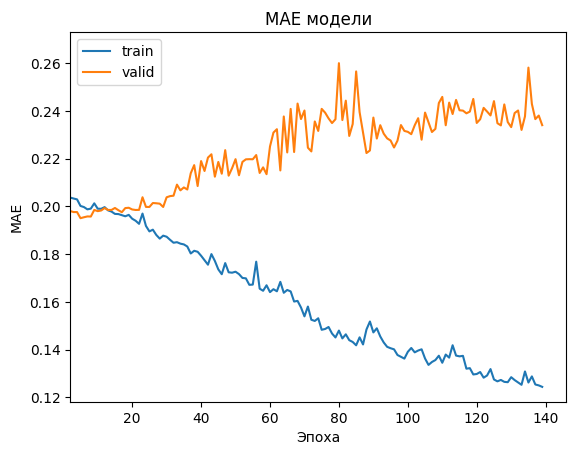

In [62]:
plt.plot(history["train"], label="train")
plt.plot(history["valid"], label="valid")

SKIP_EPOCHS = 2   # первые эпохи не показываем: ошибка там заметно выше и сжимает график
plt.xlim(SKIP_EPOCHS)
tail = history["train"][SKIP_EPOCHS:] + history["valid"][SKIP_EPOCHS:]
plt.ylim(min(tail) * 0.95, max(tail) * 1.05)
plt.xlabel("Эпоха")
plt.ylabel("MAE")
plt.title("MAE модели")

plt.legend()
plt.show()


In [63]:
print("Лучшая эпоха:", best_epoch)
print("Лучшая WMAE valid:", best_valid)

Лучшая эпоха: 6
Лучшая WMAE valid: 0.19507273


Вывод: переобучение присутствует и начинается довольно рано (примерно на 18 эпохе в данном случае). Это видно по графику train и valid. train падает в то время как ошибка в valid растет - модель заучивает имеющиеся данные.

#### Hyperparameter tuning


In [64]:
param_grid = {
    "hiddenShape": [
        [4, 2],
        [16, 8],
        [32, 16],
        [64, 32],
        # [128, 64, 32],
        [128, 128, 64, 32]
    ],

    "fActivation": [
        nn.Tanh,
        nn.ReLU,
        nn.GELU
    ],

    "lr": [
        1e-2,
        3e-3,
        1e-3,
        # 3e-4
    ],

    "batch_size": [
        16,
        32,
        64,
        # 128
    ],

    "weight_decay": [ # регуляризация. Насколько сильно надо штрафовать модель на большие веса. большие веса - слишком большой подгон модели под датасет и это борьба с переобучением
        0,
        1e-5,
        1e-4,
        # 1e-3
    ],

    "alpha": [
        0,
        0.01,
        0.05,
        # 0.1,
        # 0.25,
    ]
}

In [65]:
params = list(
    ParameterSampler(
        param_grid,
        n_iter=200,
        random_state=42
    )
)

In [66]:
TUNE_EPOCHS = 70   # сколько эпох учим каждую комбинацию при подборе

def train_model(p, x_train, y_train_norm, n_train, x_valid, y_valid, n_valid, scaler_y, loss_fn, epochs=TUNE_EPOCHS):

    # веса
    w_train = make_weight(n_train, p["alpha"])
    w_valid = make_weight(n_valid, p["alpha"])

    # DataLoader
    train_loader = DataLoader(
        TensorDataset(x_train, y_train_norm, w_train),
        batch_size=p["batch_size"],
        shuffle=True
    )

    # модель
    model = MLP(
        inputShape=x_train.shape[1],
        hiddenShape=p["hiddenShape"],
        fActivation=p["fActivation"]
    )

    # оптимизатор
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=p["lr"],
        weight_decay=p["weight_decay"]
    )

    best_valid = float("inf")
    best_epoch = 0
    best_state = None
    for epoch in range(epochs):

        model.train()

        for x, y, w in train_loader:
            optimizer.zero_grad()

            pred = model(x).squeeze(1)

            loss = weighted_loss(
                pred,
                y,
                w,
                loss_fn
            )

            loss.backward()
            optimizer.step()

        valid_wmae = evaluate(
            model,
            x_valid,
            y_valid,
            w_valid,
            scaler_y
        )

        if valid_wmae < best_valid:
            best_valid = valid_wmae
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)   # возвращаем веса лучшей эпохи

    result = {
        "score": best_valid,
        "hiddenShape": p["hiddenShape"],
        "activation": p["fActivation"].__name__,
        "lr": p["lr"],
        "batch_size": p["batch_size"],
        "best_epoch": best_epoch,
        "weight_decay": p["weight_decay"],
        "alpha": p["alpha"]
    }

    return model, result

In [67]:
results = []

for i, p in enumerate(params):

    print(f"\nКомбинация {i+1}/{len(params)}")
    print(p)

    model, result = train_model(
        p, x_train, y_train_norm, n_train,
        x_valid, y_valid, n_valid, scaler_y, LOSS_FN
    )
    results.append(result)

    print(
        f"Лучший valid WMAE: {result['score']:.6f} "
        f"(эпоха {result['best_epoch']})"
    )



Комбинация 1/200
{'weight_decay': 1e-05, 'lr': 0.01, 'hiddenShape': [32, 16], 'fActivation': <class 'torch.nn.modules.activation.ReLU'>, 'batch_size': 64, 'alpha': 0.01}
Лучший valid WMAE: 0.194982 (эпоха 5)

Комбинация 2/200
{'weight_decay': 0.0001, 'lr': 0.003, 'hiddenShape': [32, 16], 'fActivation': <class 'torch.nn.modules.activation.GELU'>, 'batch_size': 64, 'alpha': 0.01}
Лучший valid WMAE: 0.188983 (эпоха 7)

Комбинация 3/200
{'weight_decay': 1e-05, 'lr': 0.001, 'hiddenShape': [128, 128, 64, 32], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.189047 (эпоха 5)

Комбинация 4/200
{'weight_decay': 0.0001, 'lr': 0.01, 'hiddenShape': [32, 16], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 32, 'alpha': 0}
Лучший valid WMAE: 0.189803 (эпоха 27)

Комбинация 5/200
{'weight_decay': 0.0001, 'lr': 0.001, 'hiddenShape': [128, 128, 64, 32], 'fActivation': <class 'torch.nn.modules.activation.ReLU'>, 'batc

In [68]:
plt.style.use("seaborn-v0_8-whitegrid")


score = np.array([r["score"] for r in results])
epoch = np.array([r.get("best_epoch", np.nan) for r in results], dtype=float)

In [69]:
def result_col(key):
    return [tuple(r[key]) if key == "hiddenShape" else r[key] for r in results]

def uniq_order(key):
    u = set(result_col(key))
    return sorted(u, key=sum) if key == "hiddenShape" else sorted(u)

In [70]:
keys = ["hiddenShape", "activation", "lr", "batch_size", "weight_decay", "alpha"]
titles = {
    "hiddenShape": "Архитектура", "activation": "Активация", "lr": "Learning rate",
    "batch_size": "Batch size", "weight_decay": "Weight decay", "alpha": "alpha",
}
overall_mean = score.mean()
overall_med = np.median(score)

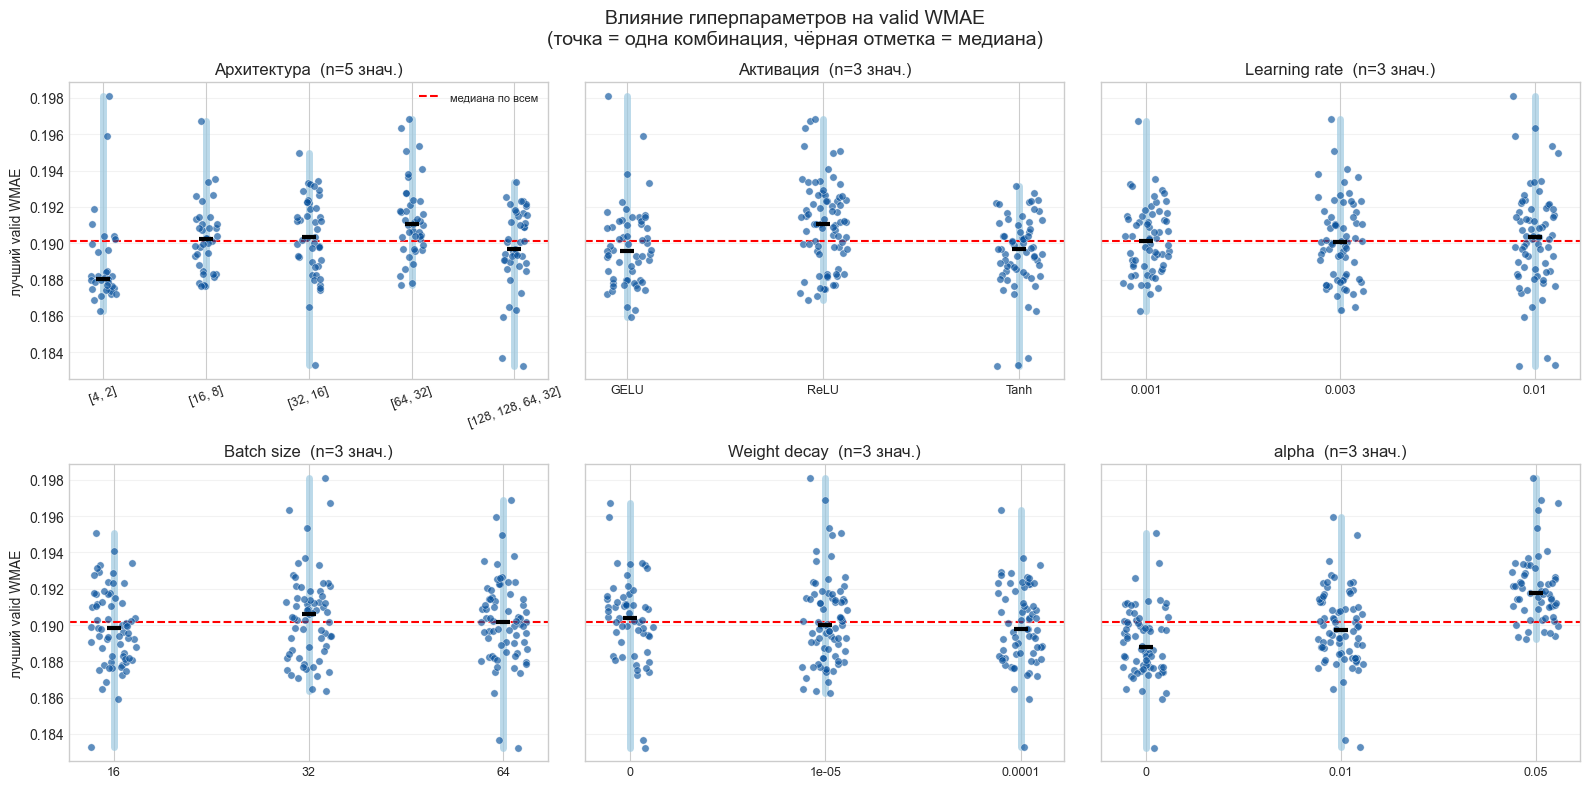

In [71]:

#  влияние каждого гиперпараметра
spread = {}  # размах средних по каждому параметру
for k in keys:
    vals = result_col(k)
    order = uniq_order(k)

    means = []

    for o in order:
        d = score[[v == o for v in vals]]
        means.append(np.mean(d))

    spread[k] = max(means) - min(means)
#  влияние каждого гиперпараметра
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
rng = np.random.default_rng(0)

for ax, k in zip(axes.ravel(), keys):
    vals = result_col(k)
    order = uniq_order(k)

    data = [score[[v == o for v in vals]] for o in order]

    # точки всех комбинаций
    for i, d in enumerate(data):
        x = i + rng.uniform(-0.12, 0.12, len(d))

        ax.scatter(
            x, d,
            s=28,
            alpha=0.65,
            color="#08519c",
            edgecolors="white",
            linewidths=0.4,
            zorder=3
        )

        # диапазон значений
        ax.plot(
            [i, i],
            [np.min(d), np.max(d)],
            color="#9ecae1",
            lw=5,
            alpha=0.7,
            zorder=1
        )

        # медиана для данного значения параметра
        ax.scatter(
            i,
            np.median(d),
            s=90,
            color="black",
            marker="_",
            linewidths=3,
            zorder=4
        )

    # общая медиана
    ax.axhline(
        overall_med,
        color="red",
        ls="--",
        lw=1.5,
        label="медиана по всем"
    )

    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(
        [str(list(o)) if k == "hiddenShape" else str(o) for o in order],
        rotation=20 if k == "hiddenShape" else 0,
        fontsize=9
    )

    ax.set_title(f"{titles[k]}  (n={len(order)} знач.)")

    ax.grid(axis="y", alpha=0.25)

axes[0, 0].set_ylabel("лучший valid WMAE")
axes[1, 0].set_ylabel("лучший valid WMAE")

axes[0, 0].legend(fontsize=8)

fig.suptitle(
    "Влияние гиперпараметров на valid WMAE\n"
    "(точка = одна комбинация, чёрная отметка = медиана)",
    fontsize=14
)

fig.tight_layout()
plt.show()

Вывод:
- архитектура со скрытым слоем [4, 2] и с [128, 128, 64, 32] показывают примерно одинаковые результаты
- ReLU показала себя по медиане хуже GELU и Tanh
- learning rate 0.01 показал себя по медиане хуже, чем 0.001, 0.003
- batch size лучшим себя показал равным 16
- weight decay лучшим себя показал 0.0001  и 0.00001
- идея с параметром alpha показала себя провальной. при alpha равным 0 лучше всего результаты

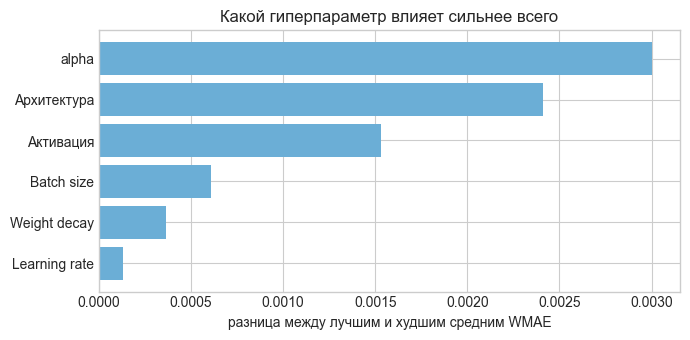

In [72]:

#  какой параметр влияет сильнее всего
fig, ax = plt.subplots(figsize=(7, 3.5))
keys_sorted = sorted(spread, key=spread.get)
ax.barh([titles[n] for n in keys_sorted], [spread[n] for n in keys_sorted], color="#6baed6")
ax.set_xlabel("разница между лучшим и худшим средним WMAE")
ax.set_title("Какой гиперпараметр влияет сильнее всего")
fig.tight_layout()
plt.show()


Вывод: alpha сильно портит результаты. Архитектура и функция активации сильно влияют на результат

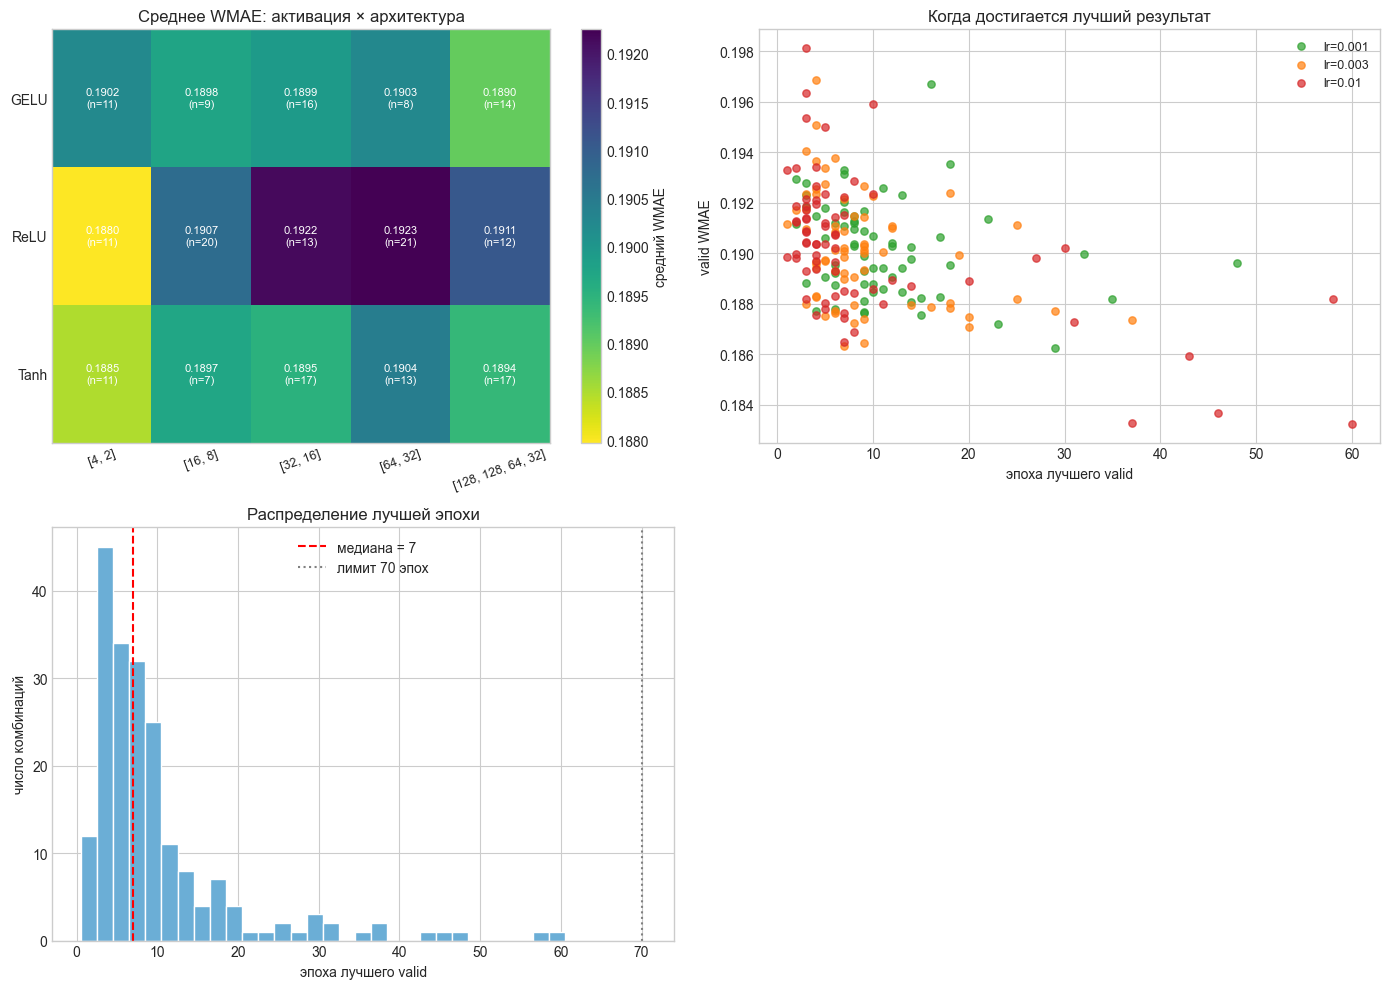

In [73]:

# общая картина
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (а) heatmap: активация x архитектура
ax = axes[0, 0]
acts = uniq_order("activation")
shapes = uniq_order("hiddenShape")
H = np.full((len(acts), len(shapes)), np.nan)
N = np.zeros(H.shape, dtype=int)
a_col, s_col = result_col("activation"), result_col("hiddenShape")
for i, a in enumerate(acts):
    for j, s in enumerate(shapes):
        m = np.array([(x == a and y == s) for x, y in zip(a_col, s_col)])
        N[i, j] = m.sum()
        if m.any():
            H[i, j] = score[m].mean()

im = ax.imshow(H, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(shapes)))
ax.set_xticklabels([str(list(s)) for s in shapes], rotation=20, fontsize=9)
ax.set_yticks(range(len(acts)))
ax.set_yticklabels(acts)
for i in range(len(acts)):
    for j in range(len(shapes)):
        if not np.isnan(H[i, j]):
            ax.text(j, i, f"{H[i, j]:.4f}\n(n={N[i, j]})", ha="center", va="center",
                    color="white", fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="средний WMAE")
ax.set_title("Среднее WMAE: активация × архитектура")

# (б) эпоха лучшего результата vs score, цвет = lr
ax = axes[0, 1]
lr_arr = np.array(result_col("lr"))
for lr_val, c in zip(uniq_order("lr"), ["#2ca02c", "#ff7f0e", "#d62728"]):
    m = lr_arr == lr_val
    ax.scatter(epoch[m], score[m], s=28, alpha=0.7, color=c, label=f"lr={lr_val}")
ax.set_xlabel("эпоха лучшего valid")
ax.set_ylabel("valid WMAE")
ax.set_title("Когда достигается лучший результат")
ax.legend(fontsize=9)

# (г) гистограмма лучших эпох
ax = axes[1, 0]
ep = epoch[~np.isnan(epoch)]
if len(ep):
    ax.hist(ep, bins=np.arange(0.5, TUNE_EPOCHS + 1.5, 2), color="#6baed6", edgecolor="white")
    ax.axvline(np.median(ep), color="red", ls="--", label=f"медиана = {np.median(ep):.0f}")
    ax.axvline(TUNE_EPOCHS, color="gray", ls=":", label=f"лимит {TUNE_EPOCHS} эпох")
    ax.set_xlabel("эпоха лучшего valid")
    ax.set_ylabel("число комбинаций")
    ax.legend()
else:
    ax.text(0.5, 0.5, "нет best_epoch в results", ha="center", va="center")
ax.set_title("Распределение лучшей эпохи")
axes[1, 1].axis("off")
fig.tight_layout()
plt.show()


Вывод:
- подтверждается, что Relu в среднем хуже, чем Tanh\GELU
- при learning rate = 0.01 модель быстрее достигает своей лучшей эпохи
- модель быстро обучается. в большинстве случаев быстрее чем за 10 эпох, что означает, что мало признаков и связи между ними линейные

In [74]:

#  топ-10 таблицей
print(f"{'#':>2} {'WMAE':>9} {'ep':>3}  config")
for rank, idx in enumerate(np.argsort(score)[:10], 1):
    r = results[idx]
    print(f"{rank:>2} {r['score']:.6f} {epoch[idx]:>3.0f}  {r['hiddenShape']} {r['activation']} "
          f"lr={r['lr']} bs={r['batch_size']} wd={r['weight_decay']} a={r['alpha']}")

 #      WMAE  ep  config
 1 0.183248  60  [128, 128, 64, 32] Tanh lr=0.01 bs=64 wd=0 a=0
 2 0.183289  37  [32, 16] Tanh lr=0.01 bs=16 wd=0.0001 a=0.01
 3 0.183667  46  [128, 128, 64, 32] Tanh lr=0.01 bs=64 wd=0 a=0.01
 4 0.185944  43  [128, 128, 64, 32] GELU lr=0.01 bs=16 wd=0.0001 a=0
 5 0.186266  29  [4, 2] Tanh lr=0.001 bs=64 wd=1e-05 a=0
 6 0.186341   7  [128, 128, 64, 32] GELU lr=0.003 bs=32 wd=1e-05 a=0
 7 0.186466   9  [128, 128, 64, 32] GELU lr=0.003 bs=32 wd=0.0001 a=0
 8 0.186493   7  [32, 16] Tanh lr=0.01 bs=16 wd=1e-05 a=0.01
 9 0.186872   8  [4, 2] ReLU lr=0.01 bs=16 wd=1e-05 a=0.01
10 0.187100  20  [4, 2] ReLU lr=0.003 bs=32 wd=1e-05 a=0


### Analysis of depth and breadth

#### Breadth

In [75]:
param_grid = {
    "hiddenShape": [
    [4, 4],
    [16, 16],
    [32, 32],
    [64, 64],
    [128, 128],
    ],

    "fActivation": [
        nn.Tanh,
    ],

    "lr": [
        0.01,
    ],

    "batch_size": [
        16,
    ],

    "weight_decay": [ # регуляризация. Насколько сильно надо штрафовать модель на большие веса. большие веса - слишком большой подгон модели под датасет и это борьба с переобучением
        0,
    ],

    "alpha": [
        0,
    ]
}

In [76]:
params = list(
    ParameterSampler(
        param_grid,
        n_iter=5,
        random_state=42
    )
)


In [77]:
results = []

for i, p in enumerate(params):

    print(f"\nКомбинация {i+1}/{len(params)}")
    print(p)

    model, result = train_model(
        p, x_train, y_train_norm, n_train,
        x_valid, y_valid, n_valid, scaler_y, LOSS_FN
    )
    results.append(result)

    print(
        f"Лучший valid WMAE: {result['score']:.6f} "
        f"(эпоха {result['best_epoch']})"
    )



Комбинация 1/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [4, 4], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.188022 (эпоха 9)

Комбинация 2/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [16, 16], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.189775 (эпоха 6)

Комбинация 3/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [32, 32], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.191788 (эпоха 2)

Комбинация 4/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [64, 64], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.193320 (эпоха 2)

Комбинация 5/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [128, 128], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.194926 (эпоха 2)


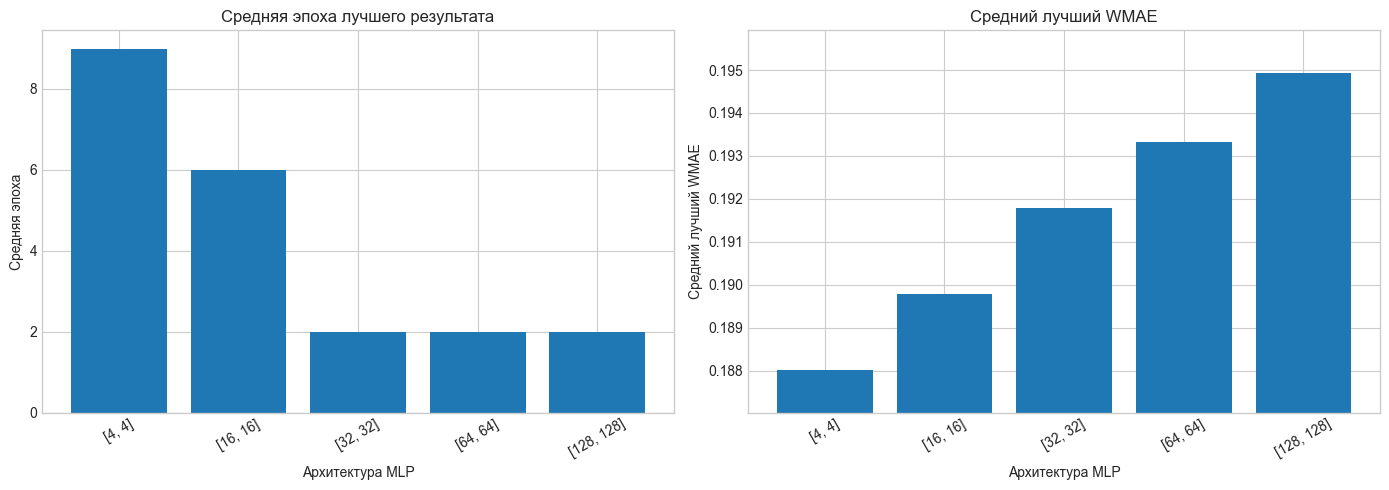

In [78]:


df_results = pd.DataFrame(results)

# Переводим архитектуру в строку для группировки
df_results["architecture"] = df_results["hiddenShape"].apply(str)

# Средняя эпоха лучшего результата
epoch_by_arch = (
    df_results
    .groupby("architecture")["best_epoch"]
    .mean()
)

# Средний лучший WMAE
score_by_arch = (
    df_results
    .groupby("architecture")["score"]
    .mean()
)

# Порядок архитектур напрямую из param_grid
architecture_order = [
    str(architecture)
    for architecture in param_grid["hiddenShape"]
]

# Переставляем в порядке из param_grid
epoch_by_arch = epoch_by_arch.reindex(architecture_order)
score_by_arch = score_by_arch.reindex(architecture_order)

# Два графика рядом
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Средняя эпоха
axes[0].bar(
    epoch_by_arch.index,
    epoch_by_arch.values
)

axes[0].set_xlabel("Архитектура MLP")
axes[0].set_ylabel("Средняя эпоха")
axes[0].set_title("Средняя эпоха лучшего результата")
axes[0].tick_params(axis="x", rotation=30)

# Средний WMAE
axes[1].bar(
    score_by_arch.index,
    score_by_arch.values
)

axes[1].set_xlabel("Архитектура MLP")
axes[1].set_ylabel("Средний лучший WMAE")
axes[1].set_title("Средний лучший WMAE")
axes[1].tick_params(axis="x", rotation=30)

# Увеличиваем масштаб, чтобы разница WMAE была заметнее
y_min = score_by_arch.min() - 0.001
y_max = score_by_arch.max() + 0.001
axes[1].set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

Вывод: 1) малые по ширине и большие показывают быструю сходимость к минимуму WMAE. 2) видно, что чем шире модель, тем хуже значение по метрике

#### Depth

In [79]:
param_grid = {
    "hiddenShape": [
    [16],
    [16, 16],
    [16, 16, 16],
    [16, 16, 16, 16],
    [16, 16, 16, 16, 16],


    ],

    "fActivation": [
        nn.Tanh,

    ],

    "lr": [
        0.01,
        # 3e-4
    ],

    "batch_size": [
        16,

        # 128
    ],

    "weight_decay": [ # регуляризация. Насколько сильно надо штрафовать модель на большие веса. большие веса - слишком большой подгон модели под датасет и это борьба с переобучением
        0,

        # 1e-3
    ],

    "alpha": [
        0,
        # 0.01,
        # 0.05,
        # 0.1,
        # 0.25,
    ]
}

In [80]:
params = list(
    ParameterSampler(
        param_grid,
        n_iter=5,
        random_state=42
    )
)

In [81]:


results = []

for i, p in enumerate(params):

    print(f"\nКомбинация {i + 1}/{len(params)}")
    print(p)

    model, result = train_model(
        p, x_train, y_train_norm, n_train,
        x_valid, y_valid, n_valid, scaler_y, LOSS_FN
    )
    results.append(result)

    print(
        f"Лучший valid WMAE: {result['score']:.6f} "
        f"(эпоха {result['best_epoch']})"
    )



Комбинация 1/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [16], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.192463 (эпоха 3)

Комбинация 2/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [16, 16], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.189338 (эпоха 3)

Комбинация 3/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [16, 16, 16], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.188178 (эпоха 3)

Комбинация 4/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [16, 16, 16, 16], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.187435 (эпоха 5)

Комбинация 5/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [16, 16, 16, 16, 16], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE:

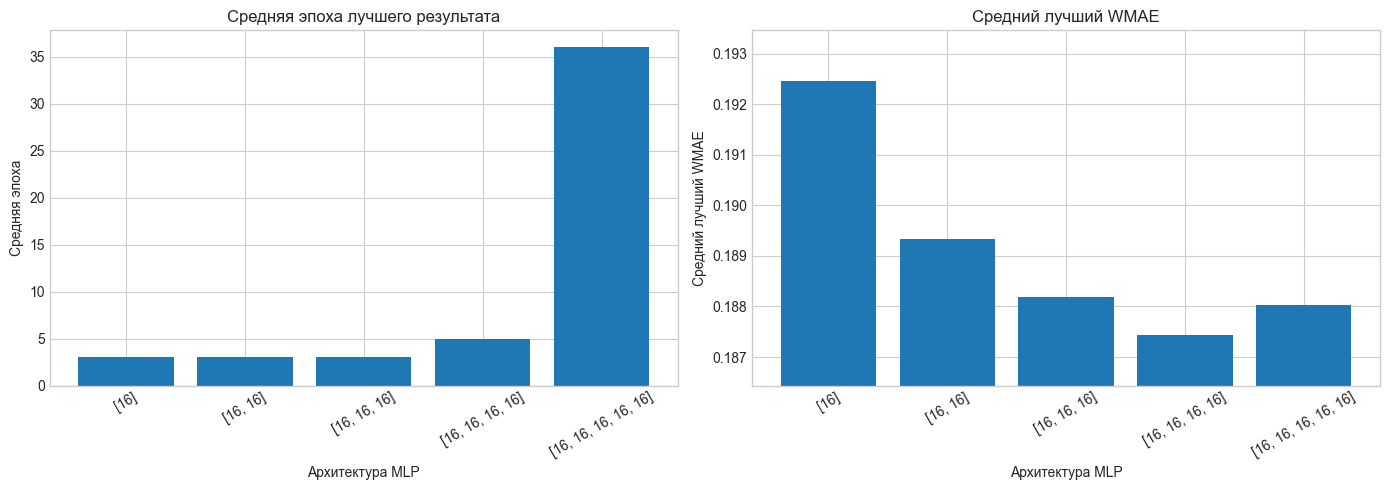

In [82]:


df_results = pd.DataFrame(results)

# Переводим архитектуру в строку для группировки
df_results["architecture"] = df_results["hiddenShape"].apply(str)

# Средняя эпоха лучшего результата
epoch_by_arch = (
    df_results
    .groupby("architecture")["best_epoch"]
    .mean()
)

# Средний лучший WMAE
score_by_arch = (
    df_results
    .groupby("architecture")["score"]
    .mean()
)

# Порядок архитектур напрямую из param_grid
architecture_order = [
    str(architecture)
    for architecture in param_grid["hiddenShape"]
]

# Переставляем в порядке из param_grid
epoch_by_arch = epoch_by_arch.reindex(architecture_order)
score_by_arch = score_by_arch.reindex(architecture_order)

# Два графика рядом
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Средняя эпоха
axes[0].bar(
    epoch_by_arch.index,
    epoch_by_arch.values
)

axes[0].set_xlabel("Архитектура MLP")
axes[0].set_ylabel("Средняя эпоха")
axes[0].set_title("Средняя эпоха лучшего результата")
axes[0].tick_params(axis="x", rotation=30)

# Средний WMAE
axes[1].bar(
    score_by_arch.index,
    score_by_arch.values
)

axes[1].set_xlabel("Архитектура MLP")
axes[1].set_ylabel("Средний лучший WMAE")
axes[1].set_title("Средний лучший WMAE")
axes[1].tick_params(axis="x", rotation=30)

# Увеличиваем масштаб, чтобы разница WMAE была заметнее
y_min = score_by_arch.min() - 0.001
y_max = score_by_arch.max() + 0.001
axes[1].set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

Вывод: 1) глубина модели практически не повлияла на скорость сходимости к минимуму по метрике. 2) более глубокая модель показала чуть лучше результат, чем менее глубокая. Но разница небольшая

#### Depth and breadth

In [83]:
param_grid = {
    "hiddenShape": [
    # совместное увеличение ширины и глубины
    [4],
    [8, 8],
    [16, 16, 16],
    [32, 32, 32, 32],
    [64, 64, 64, 64]

    ],

    "fActivation": [
        nn.Tanh,

    ],

    "lr": [
        0.01,
        # 3e-4
    ],

    "batch_size": [
        16,

        # 128
    ],

    "weight_decay": [
        # регуляризация. Насколько сильно надо штрафовать модель на большие веса. большие веса - слишком большой подгон модели под датасет и это борьба с переобучением
        0,

        # 1e-3
    ],

    "alpha": [
        0,
        # 0.01,
        # 0.05,
        # 0.1,
        # 0.25,
    ]
}


In [84]:
params = list(
    ParameterSampler(
        param_grid,
        n_iter=5,
        random_state=42
    )
)


In [85]:

results = []

for i, p in enumerate(params):

    print(f"\nКомбинация {i + 1}/{len(params)}")
    print(p)

    model, result = train_model(
        p, x_train, y_train_norm, n_train,
        x_valid, y_valid, n_valid, scaler_y, LOSS_FN
    )
    results.append(result)

    print(
        f"Лучший valid WMAE: {result['score']:.6f} "
        f"(эпоха {result['best_epoch']})"
    )



Комбинация 1/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [4], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.188499 (эпоха 2)

Комбинация 2/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [8, 8], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.189170 (эпоха 5)

Комбинация 3/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [16, 16, 16], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.190054 (эпоха 5)

Комбинация 4/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [32, 32, 32, 32], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.189227 (эпоха 3)

Комбинация 5/5
{'weight_decay': 0, 'lr': 0.01, 'hiddenShape': [64, 64, 64, 64], 'fActivation': <class 'torch.nn.modules.activation.Tanh'>, 'batch_size': 16, 'alpha': 0}
Лучший valid WMAE: 0.1873

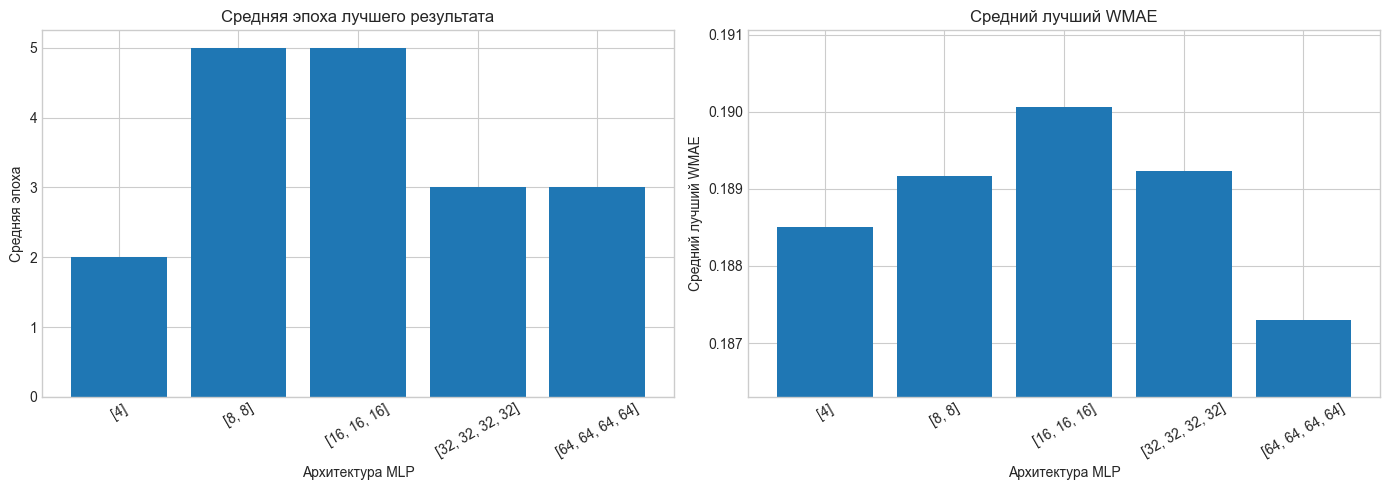

In [86]:


df_results = pd.DataFrame(results)

# Переводим архитектуру в строку для группировки
df_results["architecture"] = df_results["hiddenShape"].apply(str)

# Средняя эпоха лучшего результата
epoch_by_arch = (
    df_results
    .groupby("architecture")["best_epoch"]
    .mean()
)

# Средний лучший WMAE
score_by_arch = (
    df_results
    .groupby("architecture")["score"]
    .mean()
)

# Порядок архитектур напрямую из param_grid
architecture_order = [
    str(architecture)
    for architecture in param_grid["hiddenShape"]
]

# Переставляем в порядке из param_grid
epoch_by_arch = epoch_by_arch.reindex(architecture_order)
score_by_arch = score_by_arch.reindex(architecture_order)

# Два графика рядом
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Средняя эпоха
axes[0].bar(
    epoch_by_arch.index,
    epoch_by_arch.values
)

axes[0].set_xlabel("Архитектура MLP")
axes[0].set_ylabel("Средняя эпоха")
axes[0].set_title("Средняя эпоха лучшего результата")
axes[0].tick_params(axis="x", rotation=30)

# Средний WMAE
axes[1].bar(
    score_by_arch.index,
    score_by_arch.values
)

axes[1].set_xlabel("Архитектура MLP")
axes[1].set_ylabel("Средний лучший WMAE")
axes[1].set_title("Средний лучший WMAE")
axes[1].tick_params(axis="x", rotation=30)

# Увеличиваем масштаб, чтобы разница WMAE была заметнее
y_min = score_by_arch.min() - 0.001
y_max = score_by_arch.max() + 0.001
axes[1].set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

Вывод: 1) с увеличением и глубины, и широты, скорость сходимости уменьшается 2) с увеличением и глубины, и широты WMAE немного уменьшается. Но разница небольшая (примерно 0.002)

## Validation & test

In [87]:
#  лучшая комбинация по valid WMAE
FINAL_PARAMS = {
    "hiddenShape": [128, 128, 64, 32],
    "fActivation": nn.Tanh,
    "lr": 0.01,
    "batch_size": 64,
    "weight_decay": 0,
    "alpha": 0,
}

torch.manual_seed(SEED)
final_model, final_result = train_model(
    FINAL_PARAMS, x_train, y_train_norm, n_train,
    x_valid, y_valid, n_valid, scaler_y, LOSS_FN
)

Лучшая эпоха: 27, valid WMAE = 0.1892


In [88]:
def predict(model, x, scaler_y):
    model.eval()
    with torch.no_grad():
        pred = model(x).squeeze(1).cpu().numpy().reshape(-1, 1)
    return scaler_y.inverse_transform(pred).flatten()   # обратно в шкалу рейтинга

# константный бейзлайн: для MAE оптимальна медиана train
baseline = np.median(y_train.numpy())

sets = {
    "train": (x_train, y_train, n_train),
    "valid": (x_valid, y_valid, n_valid),
    "test": (x_test, y_test, n_test),
}

rows = []
for name, (x, y, n) in sets.items():
    pred = predict(final_model, x, scaler_y)
    y_np = y.numpy()
    rows.append({
        "выборка": name,
        "MAE модели": np.mean(np.abs(pred - y_np)),
        "WMAE модели": evaluate(final_model, x, y, make_weight(n, FINAL_PARAMS["alpha"]), scaler_y),
        "MAE константы": np.mean(np.abs(baseline - y_np)),
    })

print(pd.DataFrame(rows).round(4).to_string(index=False))

выборка  MAE модели  WMAE модели  MAE константы
  train      0.1807       0.1807         0.1984
  valid      0.1892       0.1892         0.1875
   test      0.2151       0.2151         0.1891


получилил резульат не лучше константы. Необходим более большой датасет дял лучшего обучения модели

### Gradients

In [91]:
x = x_test[0:1] # одно вино из тестовой выборки
x

tensor([[-0.2762, -0.3900, -0.4371,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  

In [92]:
# сохранять выходы слоёв
activations = {} # cловарь с выходами слоёв
hooks = [] # писок зарегистрированных хуков. хук -  функция обратного вызова

In [93]:
# функция для сохранения выхода слоя
def save_activation(name):
    def hook(module, inputs, output):
        activations[name] = output
        # module - сам слой нейросети
        # inputs - данные, которые поступили в слой
        # output - результат работы слоя
    return hook

In [94]:
# первый скрытый слой
hooks.append(
    final_model.inputModule.register_forward_hook(
        save_activation("Слой 1")
    )
)

In [95]:
# остальные скрытые слои
for i, layer in enumerate(final_model.hiddenModule):
    hooks.append(
        layer.register_forward_hook(
            save_activation(f"Слой {i + 2}")
        )
    )

In [98]:

final_model.eval()  # Переключает модель в режим оценки.

pred_norm = final_model(x).squeeze()
pred_norm

tensor(0.3975, grad_fn=<SqueezeBackward0>)

In [99]:
# Возвращаем предсказание к исходной шкале рейтинга
pred = pred_norm * scaler_y.scale_[0] + scaler_y.mean_[0]

print("Предсказанный рейтинг:", pred.item())

Предсказанный рейтинг: 5.002499580383301


In [100]:
# вычисляем градиенты предсказания по выходам каждого слоя
names = list(activations.keys()) # получаем имена слоёв
layer_outputs = [activations[name] for name in names] # получаем выходы слоёв

gradients = torch.autograd.grad(pred, layer_outputs) #  вычисление производных


# Выводим результаты
for name, grad in zip(names, gradients):
    print(f"\n{name}")
    print("Размер градиента:", grad.shape)
    print("Норма градиента:", torch.norm(grad).item())
    print("Первые 10 значений:", grad.flatten()[:10].detach().numpy())


# Удаляем хуки после вычисления
for hook in hooks:
    hook.remove()


Слой 1
Размер градиента: torch.Size([1, 128])
Норма градиента: 0.00020900244999211282
Первые 10 значений: [ 4.0081028e-05  1.4686551e-05  1.1278923e-05 -4.1440467e-06
 -1.2764153e-05  9.7955744e-06 -9.7676320e-06  2.1716780e-05
  2.3234428e-05  2.1214870e-05]

Слой 2
Размер градиента: torch.Size([1, 128])
Норма градиента: 0.0006384521257132292
Первые 10 значений: [ 2.3815895e-05  3.8739050e-05  1.9028414e-05  6.0982347e-07
 -4.3676129e-05 -3.0804007e-05  1.7373846e-05  8.6415181e-05
  1.7639697e-05  2.2429931e-05]

Слой 3
Размер градиента: torch.Size([1, 64])
Норма градиента: 0.0037855373229831457
Первые 10 значений: [-3.1821645e-04 -9.9555400e-05 -3.0074423e-04  5.4645061e-05
  4.0404580e-04 -3.7447145e-04 -7.4418564e-04 -5.1057519e-05
 -3.3474714e-04  1.0724345e-03]

Слой 4
Размер градиента: torch.Size([1, 32])
Норма градиента: 0.12104564160108566
Первые 10 значений: [ 2.8175925e-04  3.7792642e-04  1.8945271e-03 -1.6963856e-03
  2.1052493e-03 -1.5533591e-03  1.8347392e-03 -5.8915431

### Function activation

![image.png](attachment:ae6a6336-7738-468e-bfe9-0585b8934c6e.png)

In [106]:
def sigmoid(x):
  return 1 / (1 + np.exp(-x))

In [107]:
def tanh(x):
  return np.tanh(x)

In [108]:
def relu(x):
  return np.maximum(0, x)

In [109]:
def leaky_relu(x, alpha=0.1):
  return np.maximum(alpha * x, x)

In [113]:
def maxout(x, w1=1.0, b1=0.0, w2=0.5, b2=0.0):
  return np.maximum(w1 * x + b1, w2 * x + b2)

In [111]:
def elu(x, alpha=1.0):
  return np.where(x >= 0, x, alpha * (np.exp(x) - 1))

In [114]:
x = np.array([-3, -2, -1, 0, 1, 2, 3])

print("Sigmoid:   ", np.round(sigmoid(x), 4))
print("Tanh:      ", np.round(tanh(x), 4))
print("ReLU:      ", relu(x))
print("Leaky ReLU:", leaky_relu(x))
print("Maxout:    ", maxout(x))
print("ELU:       ", np.round(elu(x), 4))

Sigmoid:    [0.0474 0.1192 0.2689 0.5    0.7311 0.8808 0.9526]
Tanh:       [-0.9951 -0.964  -0.7616  0.      0.7616  0.964   0.9951]
ReLU:       [0 0 0 0 1 2 3]
Leaky ReLU: [-0.3 -0.2 -0.1  0.   1.   2.   3. ]
Maxout:     [-1.5 -1.  -0.5  0.   1.   2.   3. ]
ELU:        [-0.9502 -0.8647 -0.6321  0.      1.      2.      3.    ]


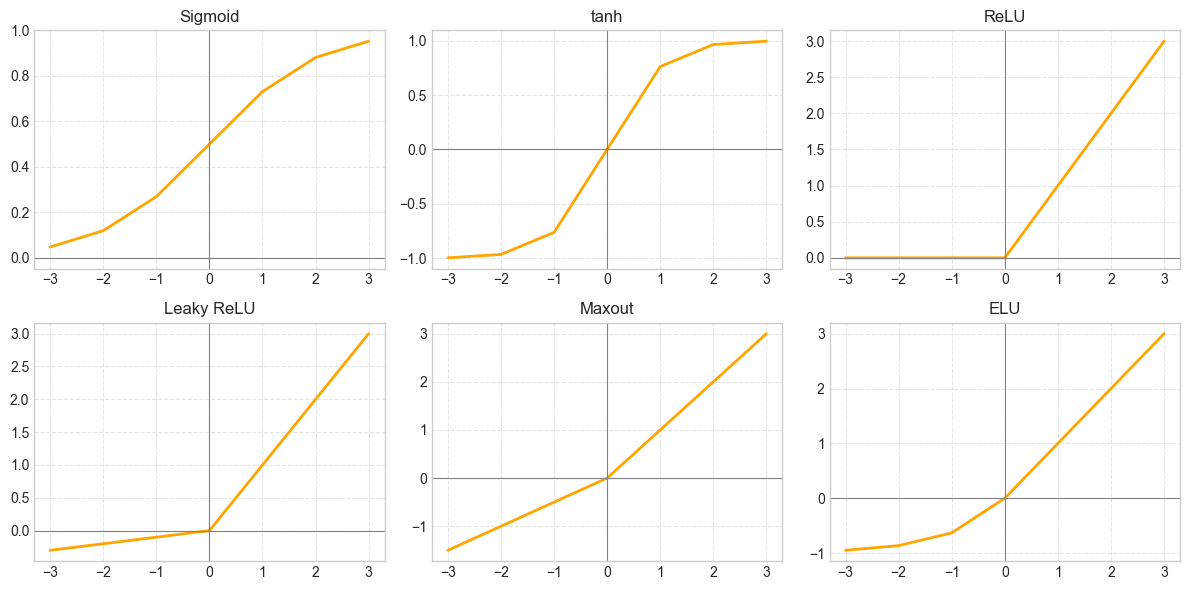

In [115]:
functions = {
    "Sigmoid": sigmoid(x),
    "tanh": tanh(x),
    "ReLU": relu(x),
    "Leaky ReLU": leaky_relu(x),
    "Maxout": maxout(x),
    "ELU": elu(x),
}

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.flatten()

for i, (name, y) in enumerate(functions.items()):
  axes[i].plot(x, y, color="orange", linewidth=2)
  axes[i].set_title(name)
  axes[i].grid(True, linestyle="--", alpha=0.5)
  axes[i].axhline(0, color="gray", linewidth=0.8)
  axes[i].axvline(0, color="gray", linewidth=0.8)

plt.tight_layout()
plt.show()